<div> <img src="https://upload.wikimedia.org/wikipedia/commons/5/55/MIDAS_Information_Technology_Co.%2C_Ltd._LOGO.png" width="200"/> </div>

# WEB OPENING

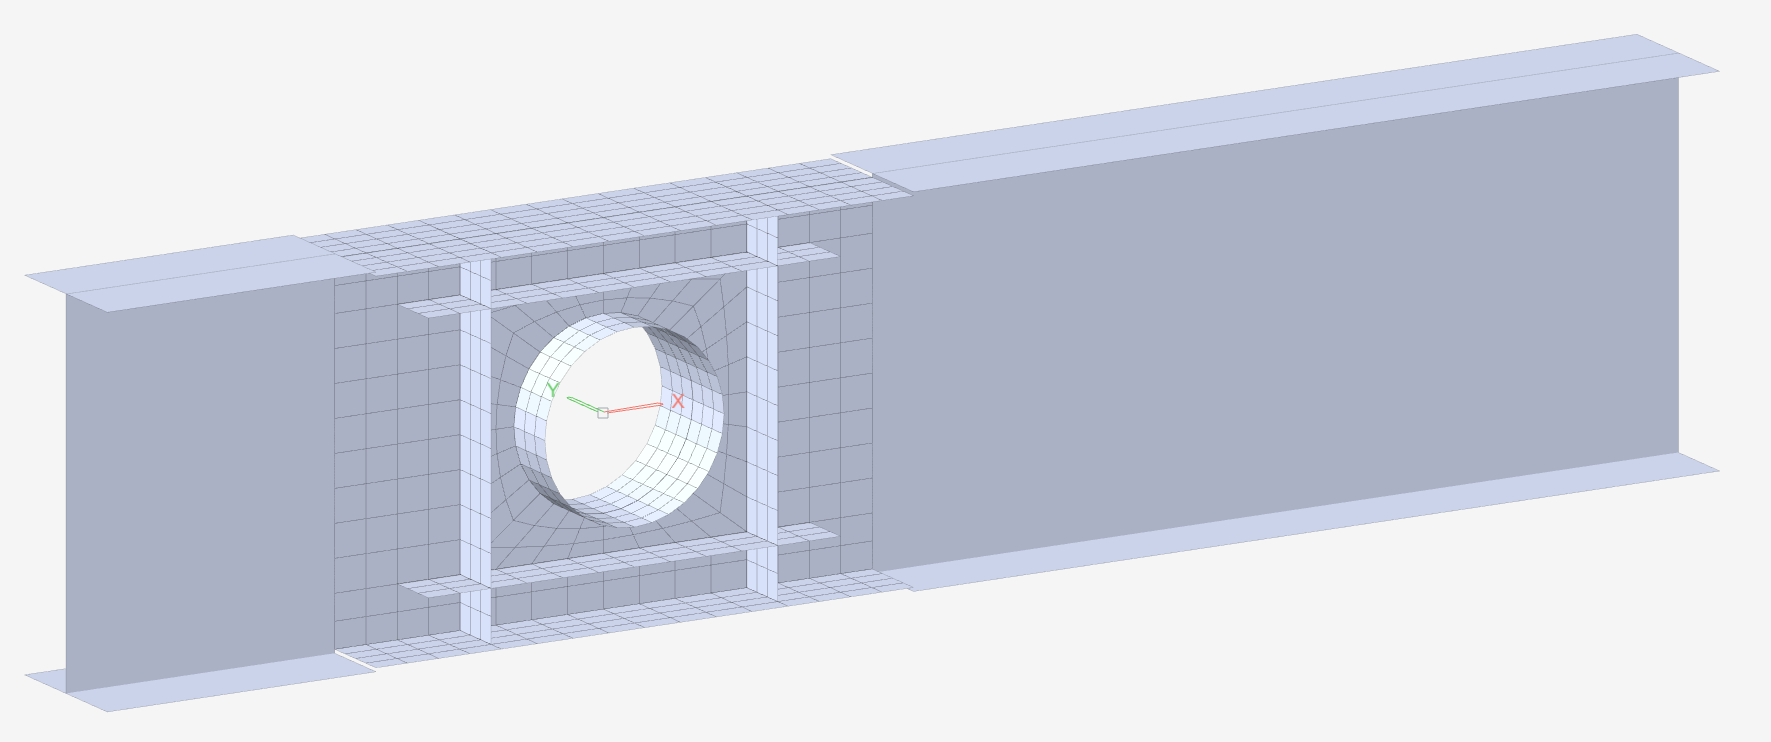



## 1. Importing Library

In [ ]:
! pip install midas_civil

## 2. Setting up

In [ ]:
from midas_civil import *
import math
MAPI_KEY("xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
MAPI_BASEURL.autoURL()
Model.units('N','M')

## 3. Modelling

Inputs
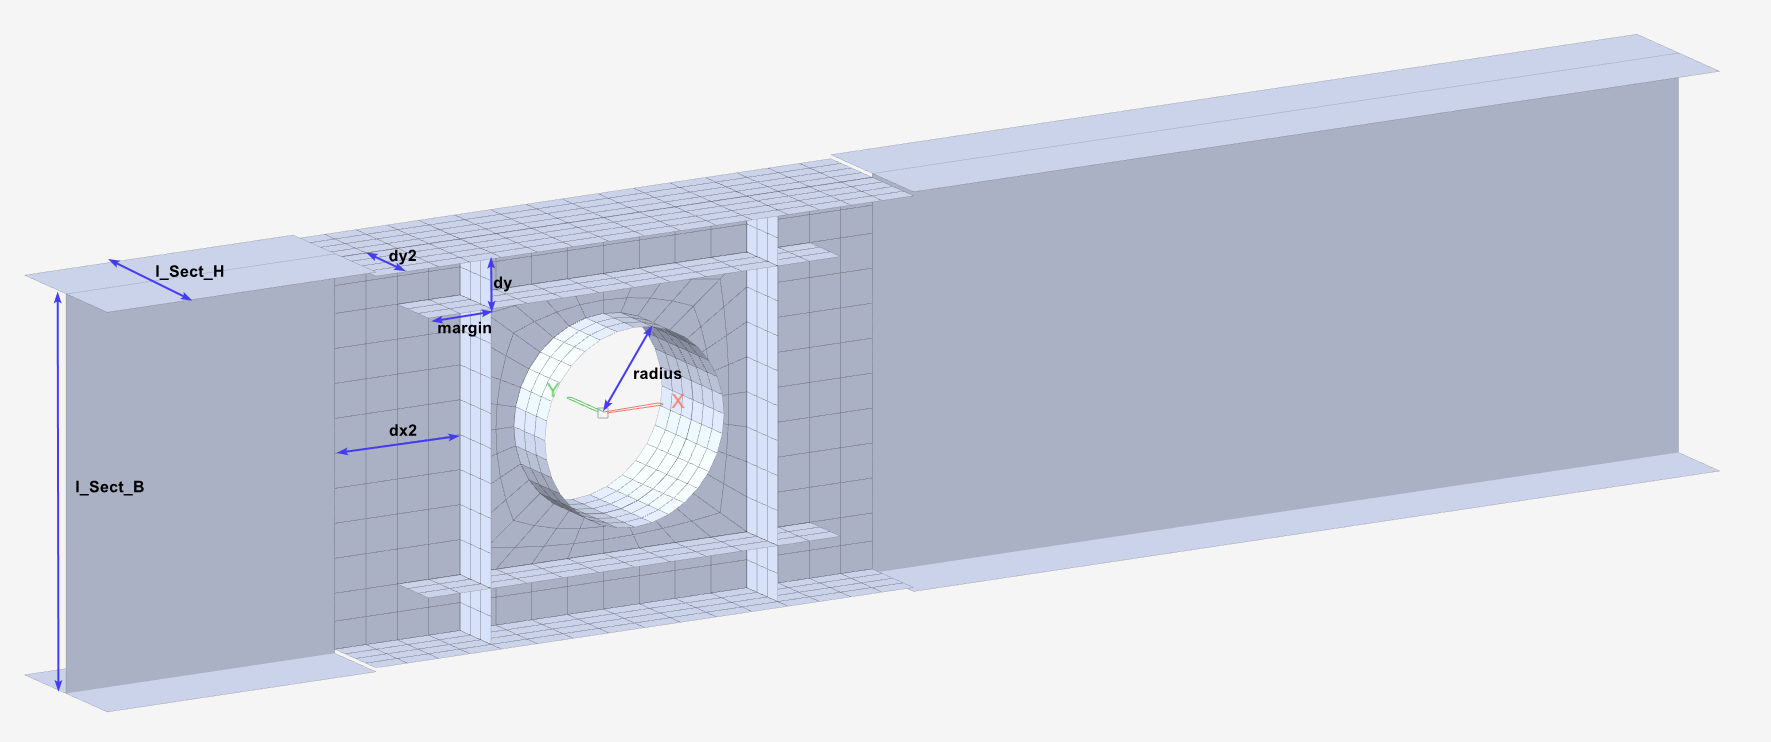 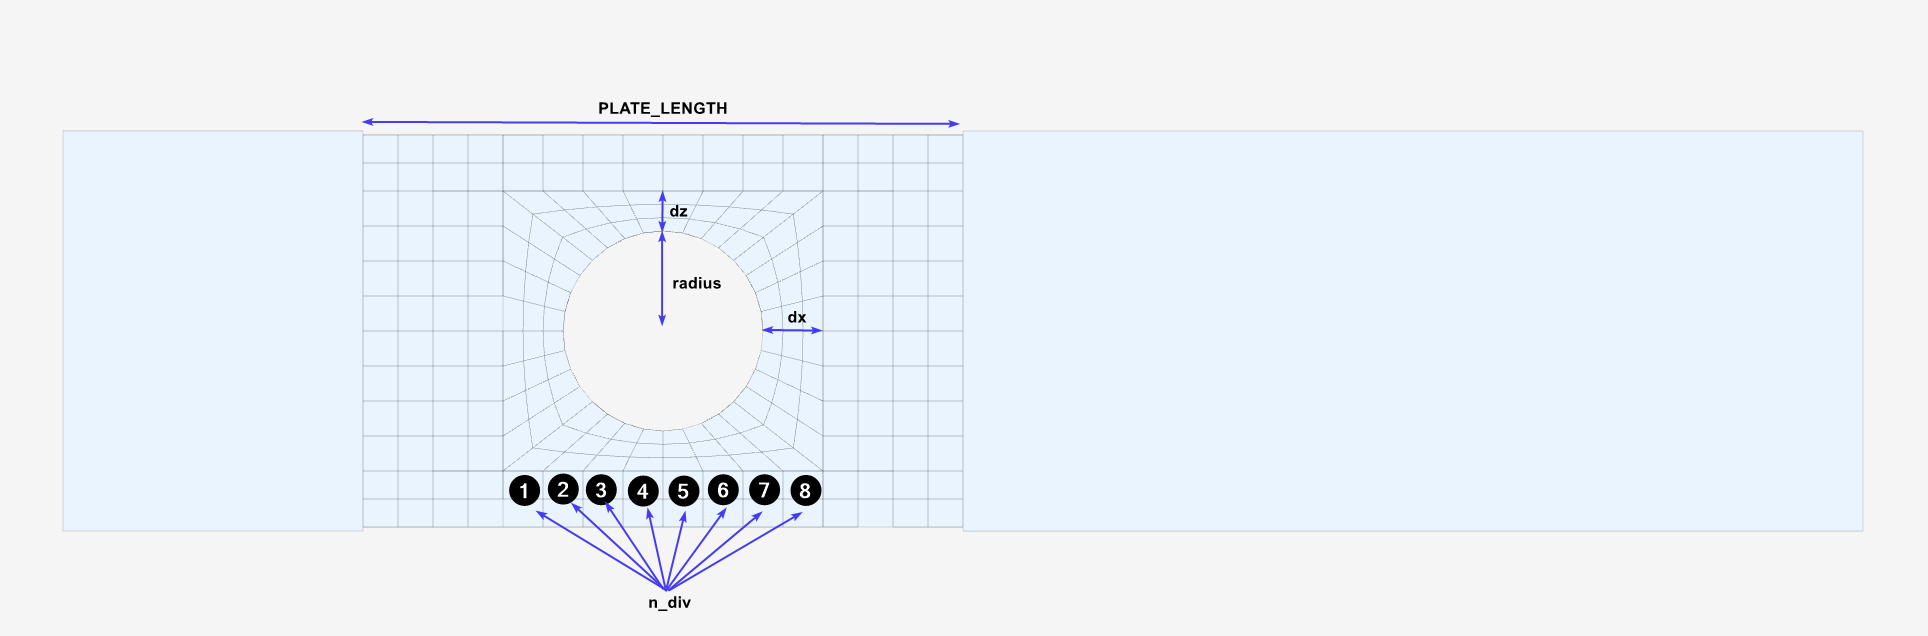

In [ ]:
circle_points = []
radius = 0.5
dx = 0.3    # Margin from circle to rect section
dz = 0.2

I_Sect_H = 2
I_Sect_B = 0.8  #EVEN
I_Sect_TW = 0.02
I_Sect_TF = 0.04

PLATE_LEN = 3
dx2 = PLATE_LEN*0.5-radius-dx
dy2=I_Sect_B/2  #0.4


dy=0.3  #Stiffner
margin = 0.35   # Longitudinal stiffner length


n_div = 8
n=4*n_div

In [ ]:
rdz = radius+dz
rdx = radius+dx

rdz2 = (I_Sect_H-I_Sect_TF)*0.5
dz2 = rdz2-rdz
rdx2 = rdx+dx2

### A. Material Properties

In [ ]:
Material.STEEL('Frame','ASTM(S)','A36')
Material.create()

### B. Section Properties

In [ ]:
Section.DBUSER('I sect','H',[I_Sect_H,I_Sect_B,I_Sect_TW,I_Sect_TF])
Section.create()
Thickness(0.01,id=1)
Thickness(0.015,id=2)
Thickness(I_Sect_TW,id=3)
Thickness(I_Sect_TF,id=4)
Thickness.create()

### C. Element Generation

This loop creates nodes in circular shape

In [ ]:
for i in range(n):
    theta = 360/n*i*math.pi/180
    circle_points.append((radius*math.sin(theta),0,radius*math.cos(theta)))
for pt in circle_points:
    Node(pt[0],pt[1],pt[2],group='Circle_I')

Creates nodes in the form of square around the circle

In [ ]:
Node.SE((0,0,rdz),(rdx,0,rdz),int(n_div*0.5),group='Circle_O')
Node.SE((rdx,0,rdz),(rdx,0,-rdz),n_div,group='Circle_O')
Node.SE((rdx,0,-rdz),(-rdx,0,-rdz),n_div,group='Circle_O')
Node.SE((-rdx,0,-rdz),(-rdx,0,rdz),n_div,group='Circle_O')
Node.SE((-rdx,0,rdz),(0,0,rdz),int(n_div*0.5),group='Circle_O')


Creates Plate elements in the region between square and circle, joining nodes of the circle and the square

In [ ]:
Element.Plate.loftGroups(['Circle_I','Circle_O'],nDiv=3,bClose=True,sect=3)

Defining a function which extrudes the element in both positive and negative Y-direction

In [ ]:
def extrude_Y_symm(nodeList,dir,ndiv,bClose,type,sect):
    Element.Plate.extrude(nodeList,(dir[0],dir[1],dir[2]),ndiv,bClose,type,sect=sect)
    Element.Plate.extrude(nodeList,(dir[0],-dir[1],dir[2]),ndiv,bClose,type,sect=sect)

Extrude top and bottom edges along Z-direction along plate length

In [ ]:
Element.Plate.extrude(Model.Select.Line((-rdx,0,rdz),(rdx,0,rdz)),(0,0,dz2),10*dz2,False,'ID',sect=3)
Element.Plate.extrude(Model.Select.Line((-rdx,0,-rdz),(rdx,0,-rdz)),(0,0,-dz2),10*dz2,False,'ID',sect=3)

Extrude side edges along X-direction

In [ ]:
Element.Plate.extrude(Model.Select.Line((-rdx,0,rdz2),(-rdx,0,-rdz2)),(-dx2,0,0),4,False,'ID',sect=3)
Element.Plate.extrude(Model.Select.Line((rdx,0,rdz2),(rdx,0,-rdz2)),(dx2,0,0),4,False,'ID',sect=3)

 Extrudes circle and side edges along Y-direction

In [ ]:
extrude_Y_symm(nodesInGroup('Circle_I'),(0,dy,0),3,True,'ID',1)
# Extrude side edges along Y
extrude_Y_symm(Model.Select.Line((-rdx,0,rdz2),(-rdx,0,-rdz2)),(0,dy,0),10*dy,False,'ID',sect=2)
extrude_Y_symm(Model.Select.Line((rdx,0,rdz2),(rdx,0,-rdz2)),(0,dy,0),10*dy,False,'ID',sect=2)

Extrude inner top and bottom edges along Y- direction

In [ ]:

extrude_Y_symm(Model.Select.Line((-rdx-margin,0,rdz),(rdx+margin,0,rdz)),(0,dy,0),10*dy,False,'ID',sect=2)
extrude_Y_symm(Model.Select.Line((-rdx-margin,0,-rdz),(rdx+margin,0,-rdz)),(0,dy,0),10*dy,False,'ID',sect=2)

Extrude outer top and bottom edges along Y-direction

In [ ]:

extrude_Y_symm(Model.Select.Line((-rdx2,0,rdz2),(rdx2,0,rdz2)),(0,dy2,0),10*dy2,False,'ID',sect=4)
extrude_Y_symm(Model.Select.Line((-rdx2,0,-rdz2),(rdx2,0,-rdz2)),(0,dy2,0),10*dy2,False,'ID',sect=4)

Creates Beam elements

In [ ]:

Element.Beam.SE((-rdx2,0,0),(-3,0,0),group='Beam')
Element.Beam.SE((rdx2,0,0),(6,0,0),group='Beam')

Creates nodes and elements in MIDAS CIVIL NX

In [ ]:
Node.create()
Element.create()

### D. Supports

Creates Rigid links between top slave nodes and mid master node
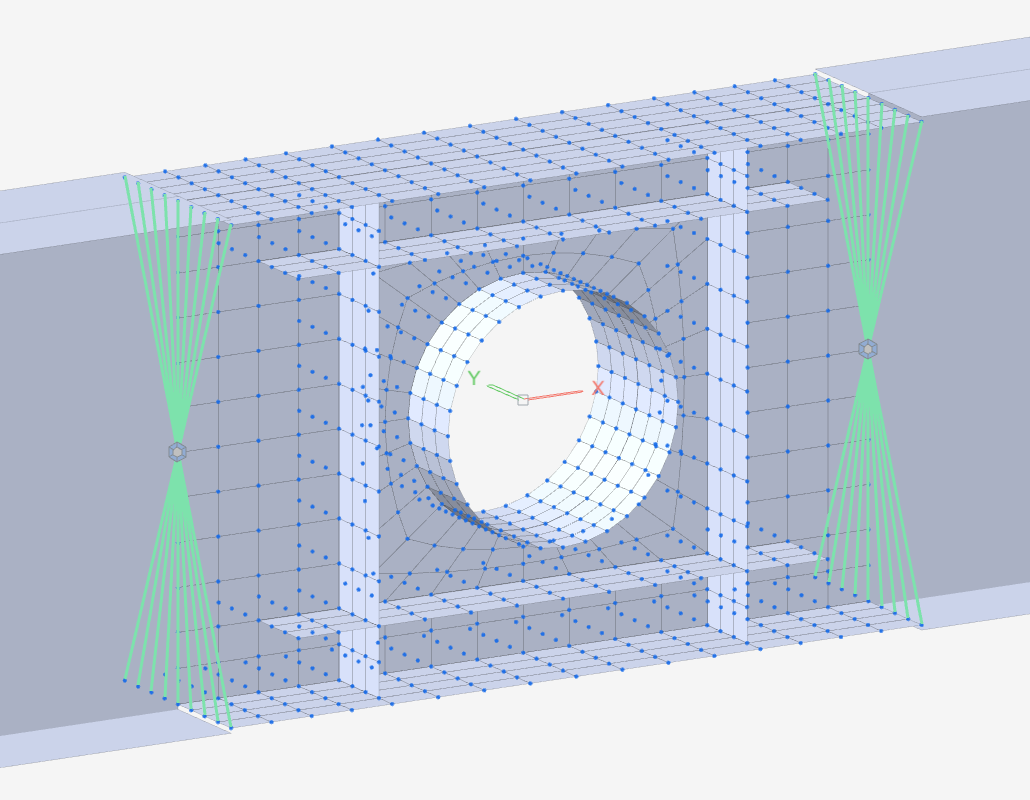

In [ ]:
slave_select = Model.Select.Box((rdx2,-dy2,-rdz2),(rdx2,dy2,rdz2))
master_1 = Node(rdx2,0,0).ID
slave_1 = [x for x in slave_select if x != master_1]

slave_select = Model.Select.Box((-rdx2,-dy2,-rdz2),(-rdx2,dy2,rdz2))
master_2 = Node(-rdx2,0,0).ID
slave_2 = [x for x in slave_select if x != master_2]

Boundary.RigidLink(master_1,slave_1)
Boundary.RigidLink(master_2,slave_2)

Support conditions are assigned to beam ends
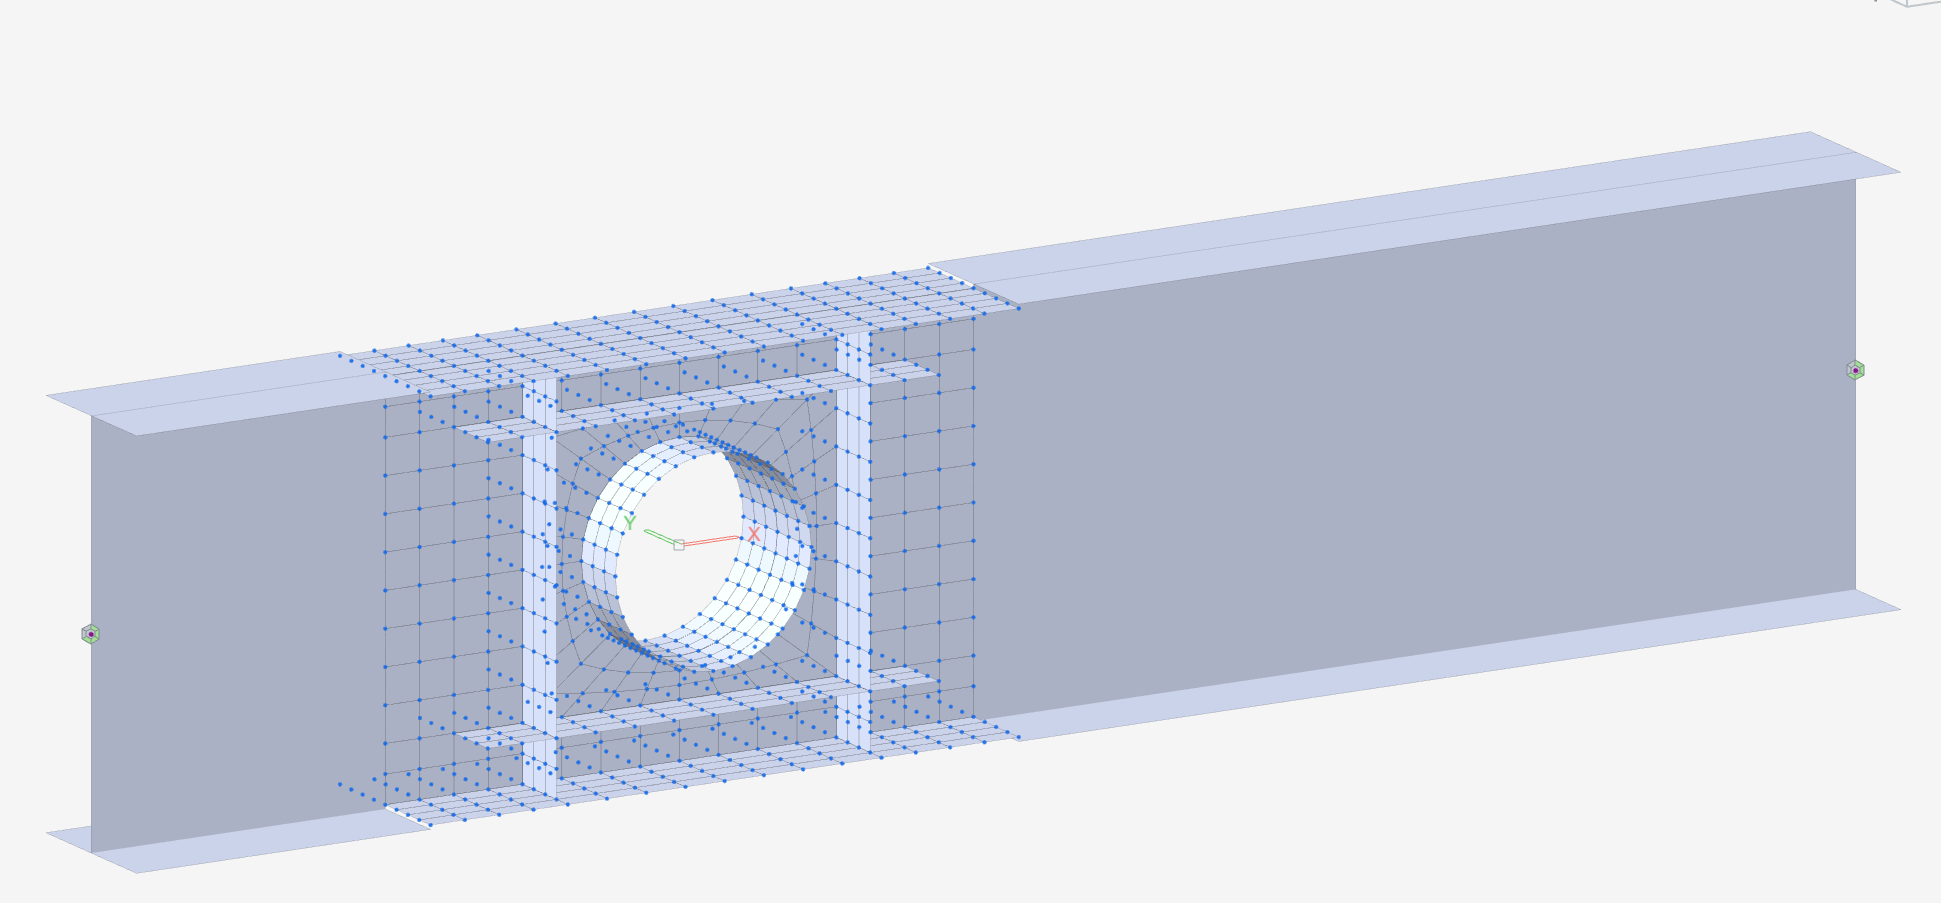

In [ ]:
Boundary.Support([Node(-3,0,0).ID,Node(6,0,0).ID],"1111000")
Boundary.create()

### E. Loading

Creates Static Load Cases

In [ ]:
Load_Case("USER","Load")
Load_Case.create()



Nodal loads are applied on top center nodes
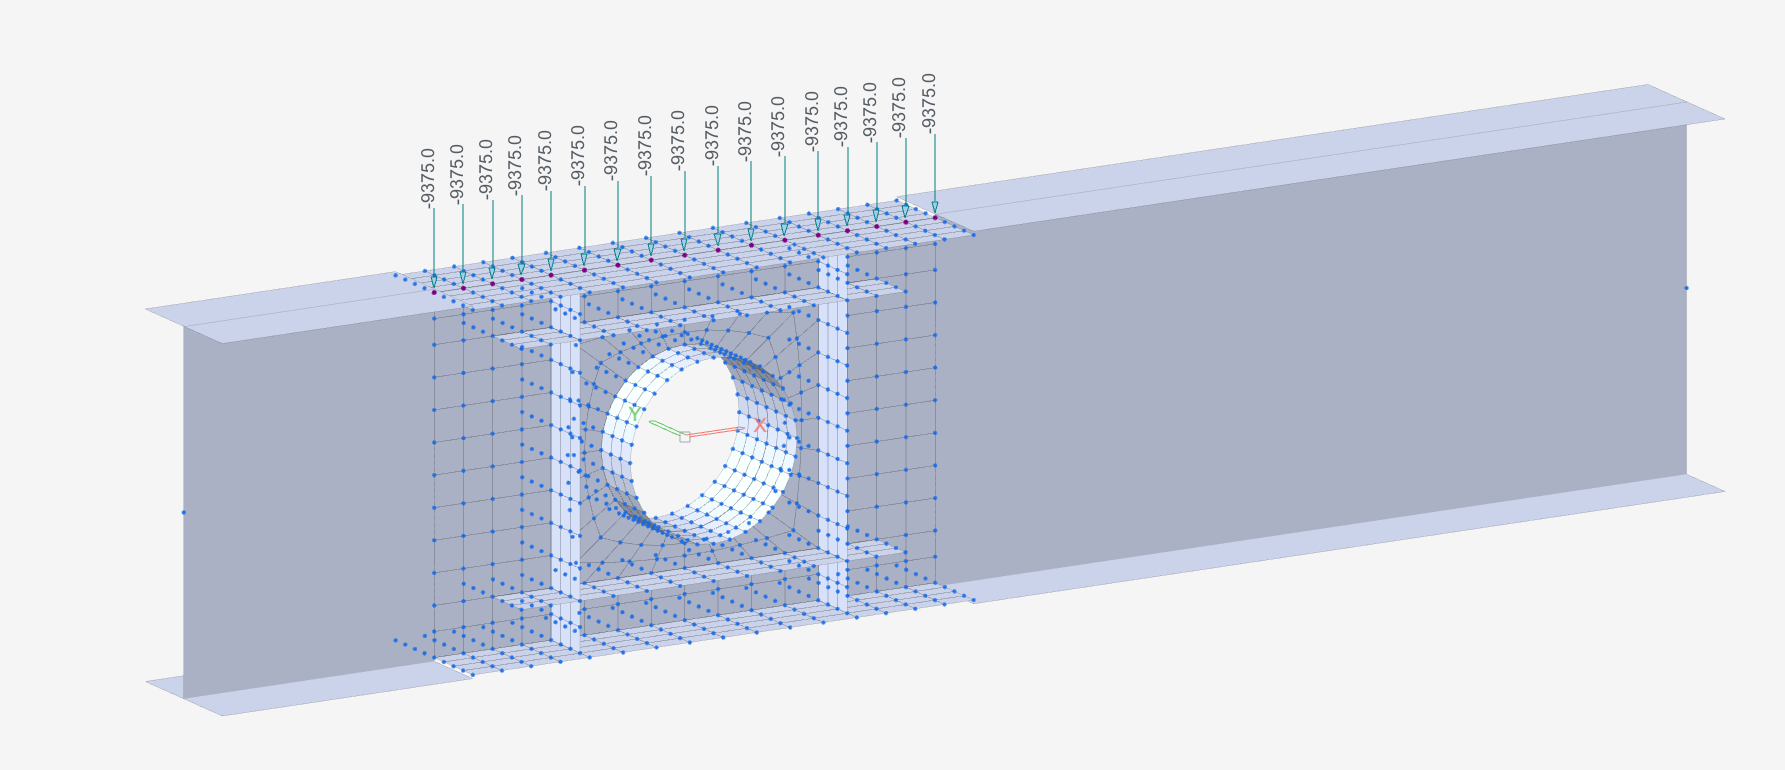

In [ ]:
Load.Nodal(Model.Select.Line((-rdx2,0,rdz2),(rdx2,0,rdz2)),'Load','',FZ=-9375)
Load.Nodal.create()

Beam Loads are applied on beams
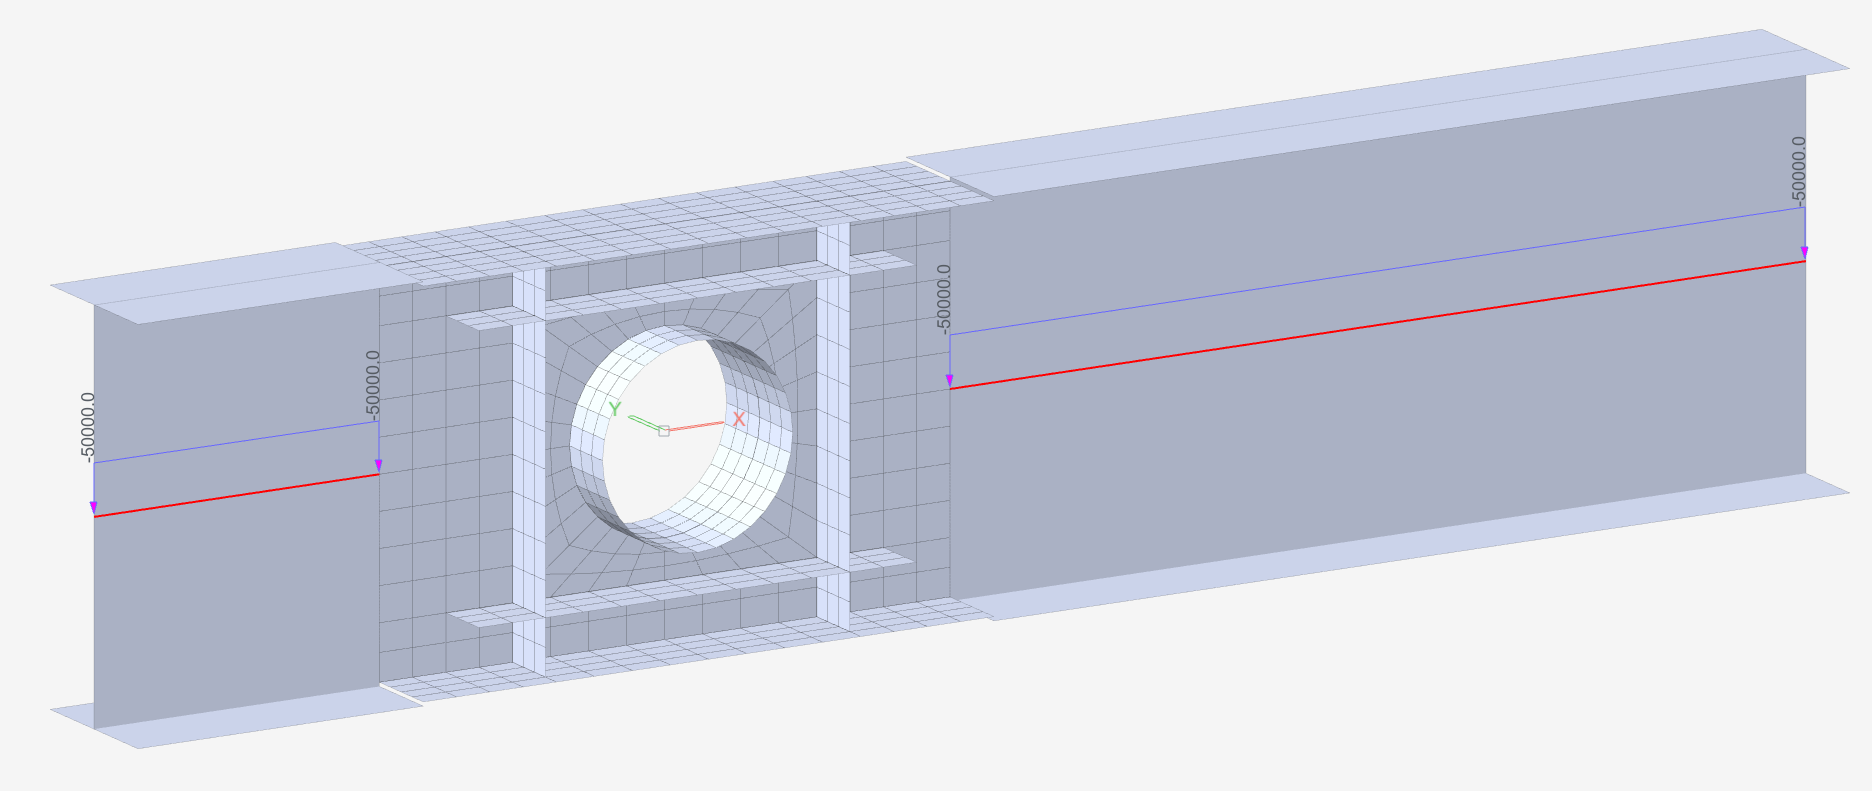

In [ ]:

Load.Beam(elemsInGroup('Beam'),'Load','',-50000)
Load.Beam.create()